In [3]:
import numpy as np
import pandas as pd
from scipy import stats

In [4]:
data = pd.read_csv("penyakit_jantung.csv")
thalach = data["thalach"]
thalach.head()

0    150
1    187
2    172
3    178
4    163
Name: thalach, dtype: int64

MEAN


In [5]:
mean = np.mean(thalach)
print("Mean:", mean)

Mean: 149.64686468646866


In [6]:
mean = sum(thalach) / len(thalach)
print("Mean:", mean)

Mean: 149.64686468646866


MEDIAN


In [7]:
median = np.median(thalach)
print("Median:", median)

Median: 153.0


In [8]:
sorted_data = np.sort(thalach)
n = len(sorted_data)
if n % 2 == 0:
    median = (sorted_data[n//2 - 1] + sorted_data[n//2]) / 2
else:
    median = sorted_data[n//2]

print("Median:", median)

Median: 153


MODE


In [9]:
mode = stats.mode(thalach)
print("Mode:", mode[0])

Mode: 162


In [10]:
values, counts = np.unique(thalach, return_counts=True)
index = np.argmax(counts)
mode = values[index]

for value, count in zip(values, counts):
    if count == counts.max():
        print(f"Mode = {value}")

Mode = 162


In [11]:
values, counts = np.unique(thalach, return_counts=True)

for value, count in zip(values, counts):
    if count == counts.max():
        print(f"Mode = {value}")

Mode = 162


In [12]:
mode_result = pd.Series(thalach).mode()
print("Mode:", mode_result.tolist())

Mode: [162]


VARIANS


In [13]:
variance = np.var(thalach)
print("Variance:", variance)

Variance: 522.9148994107331


In [14]:
mean = sum(thalach) / len(thalach)
variance = sum((x - mean) ** 2 for x in thalach) / len(thalach)
print("Variance:", variance)

Variance: 522.9148994107331


STANDAR DEVIASI


In [15]:
std_dev = np.std(thalach)
print("Standard Deviation:", std_dev)


Standard Deviation: 22.86733258188924


In [16]:
mean = sum(thalach) / len(thalach)
std = np.sqrt(sum((x - mean) ** 2 for x in thalach) / len(thalach))
print("Standar deviation :", std)

Standar deviation : 22.86733258188924


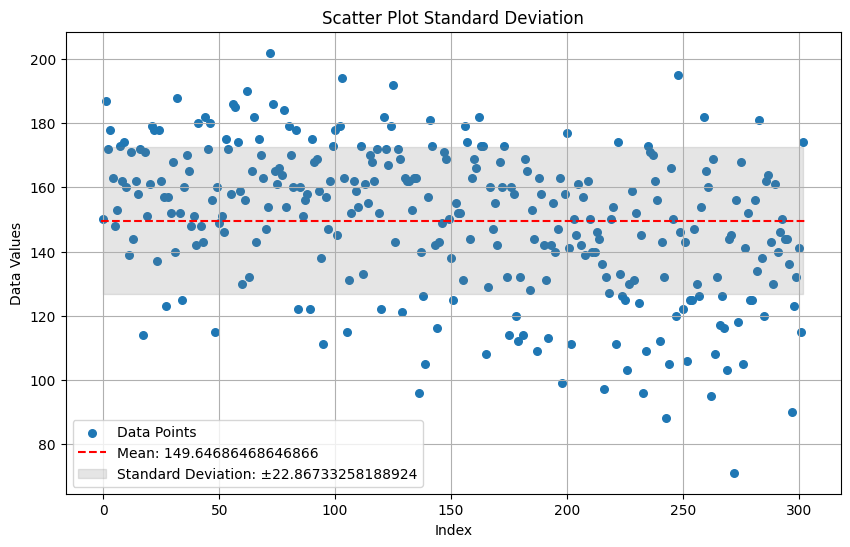

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(np.arange(len(thalach)), thalach, s=30, label='Data Points')
plt.hlines(mean, xmin=-1, xmax=len(thalach), colors='r', linestyles='dashed', label=f'Mean: {mean}')
plt.fill_between(np.arange(len(thalach)), mean - std, mean + std, color='gray', alpha=0.2, label=f'Standard Deviation: ±{std}')
plt.title('Scatter Plot Standard Deviation')
plt.xlabel('Index')
plt.ylabel('Data Values')
plt.legend()
plt.grid(True)
plt.show()


SKEWNESS


In [18]:
skewness = stats.skew(thalach)
print("Skewness:", skewness)


Skewness: -0.5347455419075503


In [19]:
mean = sum(thalach) / len(thalach)
std = np.sqrt(sum((x - mean) ** 2 for x in thalach) / len(thalach))
skewness = (sum((x - mean) ** 3 for x in thalach) / len(thalach)) / (std ** 3)
print("Skewness:", skewness)

Skewness: -0.5347455419075504


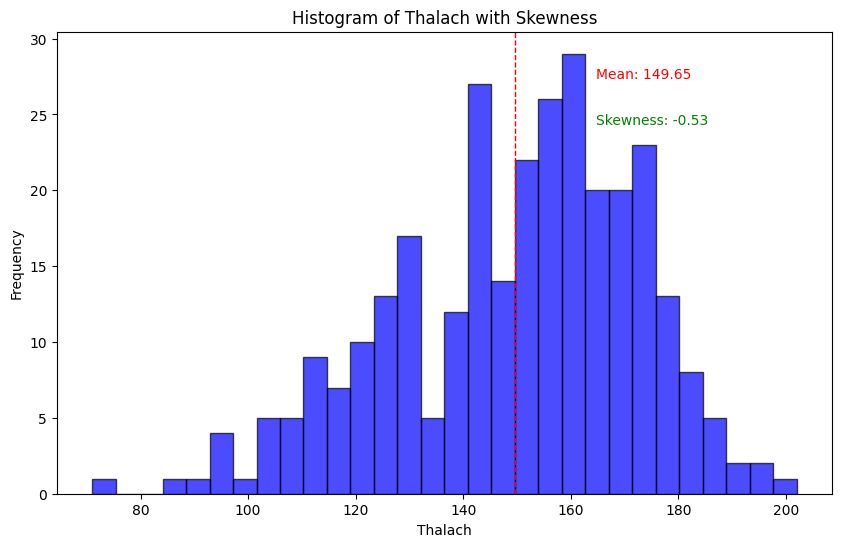

In [20]:
import matplotlib.pyplot as plt

mean = thalach.mean()
skewness = stats.skew(thalach)

# Membuat plot histogram untuk mengetahui arah condong data
plt.figure(figsize=(10, 6))
plt.hist(thalach, bins=30, alpha=0.7, color='blue', edgecolor='black')

# Menambahkan garis vertikal untuk mean
plt.axvline(mean, color='red', linestyle='dashed', linewidth=1)
min_ylim, max_ylim = plt.ylim()
plt.text(mean*1.1, max_ylim*0.9, f'Mean: {mean:.2f}', color='red')

# Menambahkan informasi skewness
plt.title('Histogram of Thalach with Skewness')
plt.xlabel('Thalach')
plt.ylabel('Frequency')
plt.text(mean*1.1, max_ylim*0.8, f'Skewness: {skewness:.2f}', color='green')

plt.show()

In [24]:
thalach

0      150
1      187
2      172
3      178
4      163
      ... 
298    123
299    132
300    141
301    115
302    174
Name: thalach, Length: 303, dtype: int64

KUARTIL


In [33]:
# mengurutkan data secara ascending
data = thalach.sort_values()

# Menghitung Q1, Q2 (Median), dan Q3 menggunakan numpy
Q1 = np.percentile(data, 25)
Q2 = np.percentile(data, 50)
Q3 = np.percentile(data, 75)

# Menghitung IQR
IQR = Q3 - Q1

# Menentukan batas bawah dan atas untuk outlier
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Median (Q2): {Q2}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

Q1: 133.5
Median (Q2): 153.0
Q3: 166.0
IQR: 32.5
Lower Bound: 84.75
Upper Bound: 214.75


In [31]:
# Mengidentifikasi outlier
outliers = [x for x in thalach if x < lower_bound or x > upper_bound]
outliers

[71]

In [32]:
df_no_outliers = thalach[(thalach >= lower_bound) & (thalach <= upper_bound)]
df_no_outliers

0      150
1      187
2      172
3      178
4      163
      ... 
298    123
299    132
300    141
301    115
302    174
Name: thalach, Length: 302, dtype: int64